In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import matplotlib as mpl
import seaborn as sns
%matplotlib inline 
import warnings
warnings.filterwarnings('ignore')

In [32]:
t1=pd.read_csv("/kaggle/input/datasets/iramnoorn25/titanic123/Titanic-Dataset.csv")


In [33]:
t1.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [36]:
t1.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [37]:
t1.isna()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False
887,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False
889,False,False,False,False,False,False,False,False,False,False,False,False


In [38]:
t1.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [39]:
t1.duplicated().sum()

np.int64(0)

In [40]:
t1.drop_duplicates(inplace=True)

In [41]:
t1.duplicated().sum()

np.int64(0)

In [42]:
t1.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [43]:
t3=["Cabin","Embarked"]
t1[t3]= t1[t3].fillna(t1[t3].mode().iloc[0])

In [44]:
t1.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin            0
Embarked         0
dtype: int64

In [45]:
t1["Age"]=t1[["Age"]].fillna(0)

In [46]:
t1.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [47]:
t1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    object 
 11  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [49]:
# Overall survival rate
overall_survival = t1["Survived"].mean() * 100

print("\nOverall Survival Rate:")
print(overall_survival)


# Survival by sex
survival_by_sex = t1.groupby("Sex")["Survived"].mean() * 100

print("\nSurvival Rate by Sex:")
print(survival_by_sex)



Overall Survival Rate:
38.38383838383838

Survival Rate by Sex:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


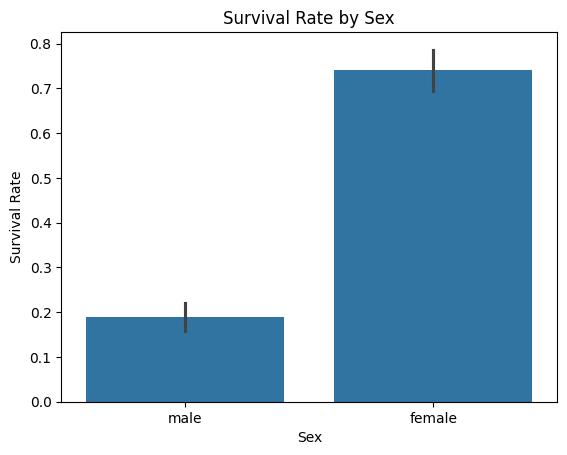

In [51]:
# Bar chart: survival by sex
sns.barplot(x="Sex", y="Survived", data=t1)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")

plt.show()


In [52]:
# Survival by class
survival_by_class = t1.groupby("Pclass")["Survived"].mean() * 100

print("\nSurvival Rate by Class:")
print(survival_by_class)



Survival Rate by Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


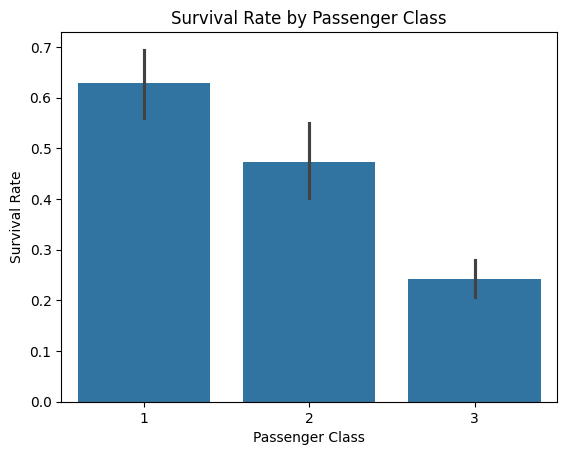

In [53]:
# Bar chart: survival by class
sns.barplot(x="Pclass", y="Survived", data=t1)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()


In [55]:
t1["AgeBucket"] = pd.cut(
    t1["Age"],
    bins=[0, 12, 18, 30, 50, 100],
    labels=[
        "Child (0-12)",
        "Teen (13-18)",
        "Young Adult (19-30)",
        "Adult (31-50)",
        "Senior (51+)"
    ],
    include_lowest=True
)



In [56]:
# Survival by age bucket
survival_by_age = t1.groupby(
    "AgeBucket",
    observed=True
)["Survived"].mean() * 100

print("\nSurvival Rate by Age Group:")
print(survival_by_age)



Survival Rate by Age Group:
AgeBucket
Child (0-12)           37.398374
Teen (13-18)           42.857143
Young Adult (19-30)    35.555556
Adult (31-50)          42.323651
Senior (51+)           34.375000
Name: Survived, dtype: float64


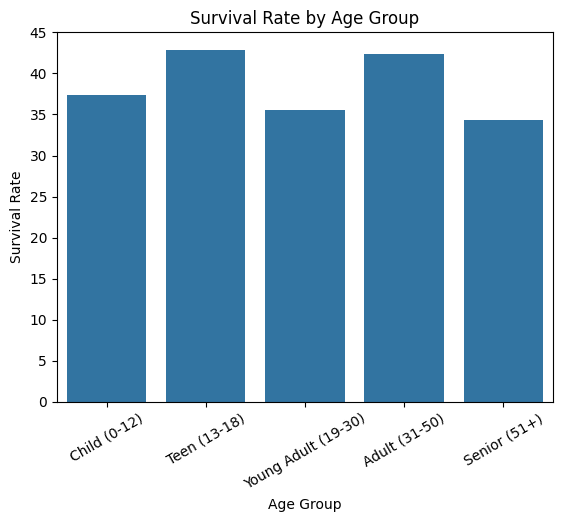

In [57]:
# Bar chart: survival by age
sns.barplot(
    x=survival_by_age.index,
    y=survival_by_age.values
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")

plt.xticks(rotation=30)

plt.show()

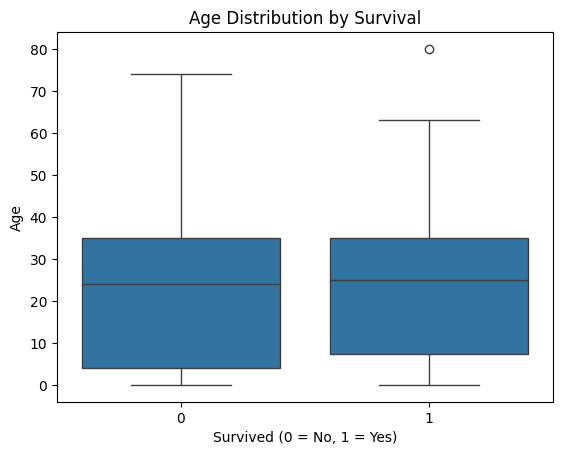

In [58]:
# Boxplot
sns.boxplot(
    x="Survived",
    y="Age",
    data=t1
)

plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()


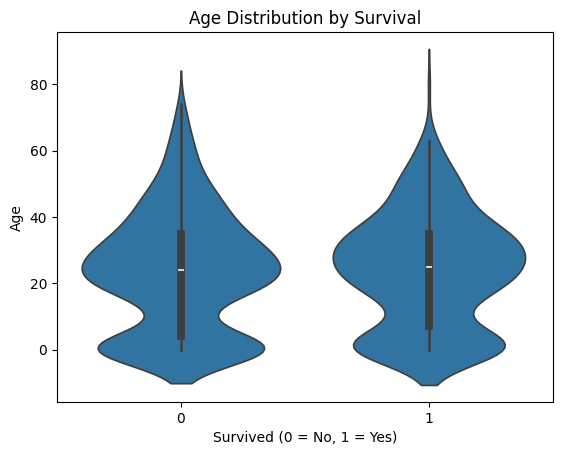

In [59]:
# Violin plot
sns.violinplot(
    x="Survived",
    y="Age",
    data=t1
)

plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

In [60]:
# Survival by sex and class
survival_sex_class = t1.groupby(
    ["Sex", "Pclass"]
)["Survived"].mean() * 100

print("\nSurvival Rate by Sex and Class:")
print(survival_sex_class)



Survival Rate by Sex and Class:
Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64


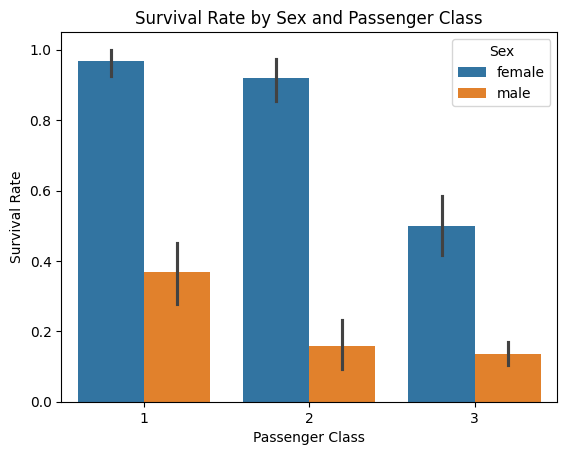

In [61]:
# Bar chart: sex and class
sns.barplot(
    x="Pclass",
    y="Survived",
    hue="Sex",
    data=t1
)

plt.title("Survival Rate by Sex and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

Short insight report
Overall survival: About 38.4% of passengers in the dataset survived.
Sex: Female passengers had a much higher survival rate (~74.2%) than male passengers (~18.9%).
Passenger class: Survival decreased from 1st class (~63.0%) to 2nd class (~47.3%) and 3rd class (~24.2%).
Age: Children had a survival rate of about 58%, while the young-adult and senior groups had lower rates in this bucketing.
Combined effect: The dataset shows substantial differences when sex and passenger class are considered together; for example, female 1st-class passengers had a survival rate of about 96.8%, while male 3rd-class passengers had about 13.5%.